In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [5]:
from google.colab import files
uploaded = files.upload()
import io
df = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

print("Dataset shape:", df.shape)

display(df.head())

Saving ecommerce_customer_segmentation_apr2024_mar2025_80000 (1).csv to ecommerce_customer_segmentation_apr2024_mar2025_80000 (1) (1).csv
Dataset shape: (80000, 7)


,Transaction_ID,Customer_ID,Transaction_Date,Amount_INR,Product_Category,Customer_Age,City
0,TXN0053575,CUST02682,2024-04-01,1205.46,Toys,35,Chennai
1,TXN0079734,CUST11579,2024-04-01,1217.63,Fashion,18,Delhi
2,TXN0039161,CUST02393,2024-04-01,591.72,Beauty,57,Jaipur
3,TXN0017404,CUST00329,2024-04-01,887.83,Books,62,Kolkata
4,TXN0041214,CUST07033,2024-04-01,5504.36,Fashion,64,Pune


In [6]:
print(df.info())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

df["Transaction_Date"] = pd.to_datetime(
    df["Transaction_Date"]
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    80000 non-null  object 
 1   Customer_ID       80000 non-null  object 
 2   Transaction_Date  80000 non-null  object 
 3   Amount_INR        80000 non-null  float64
 4   Product_Category  80000 non-null  object 
 5   Customer_Age      80000 non-null  int64  
 6   City              80000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 4.3+ MB
None
Transaction_ID      0
Customer_ID         0
Transaction_Date    0
Amount_INR          0
Product_Category    0
Customer_Age        0
City                0
dtype: int64
Duplicate rows: 0


In [7]:
reference_date = (
    df["Transaction_Date"].max()
    + pd.Timedelta(days=1)
)

rfm = df.groupby("Customer_ID").agg(
    Last_Purchase=("Transaction_Date", "max"),
    Frequency=("Transaction_ID", "nunique"),
    Monetary=("Amount_INR", "sum")
)

rfm["Recency"] = (
    reference_date - rfm["Last_Purchase"]
).dt.days

rfm = rfm[["Recency", "Frequency", "Monetary"]]

display(rfm.head())

,Recency,Frequency,Monetary
Customer_ID,,,
CUST00001,9,10,18172.28
CUST00002,25,15,32469.82
CUST00003,146,8,71678.01
CUST00004,28,7,4678.27
CUST00005,177,1,3410.57


In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(rfm)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (11841, 3)


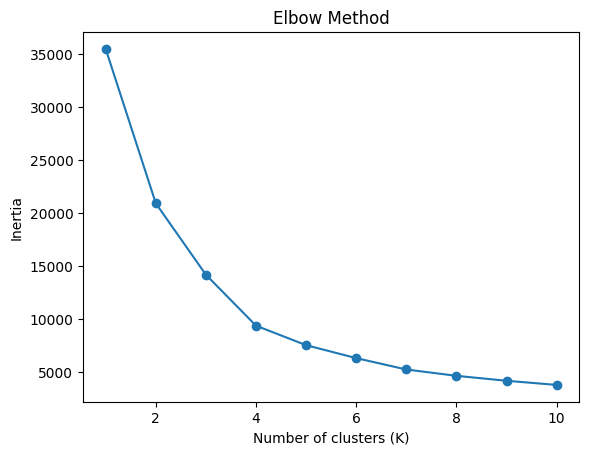

In [9]:
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [10]:
kmeans = KMeans(
    n_clusters=4,  # Change after examining the elbow
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(rfm["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    2511
1    2486
2    5738
3    1106
Name: count, dtype: int64


In [11]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1       34
 0    11802
 1        5
Name: count, dtype: int64


In [16]:
from sklearn.metrics import silhouette_score


sil_score = silhouette_score(X_scaled, rfm["KMeans_Cluster"])

print("K-Means Model Evaluation")

print("Number of clusters:", rfm["KMeans_Cluster"].nunique())
print("Silhouette Score:", round(sil_score, 4))
print("Inertia:", round(kmeans.inertia_, 2))

K-Means Model Evaluation
Number of clusters: 4
Silhouette Score: 0.4407
Inertia: 9379.55


In [12]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.62171434 0.24543565]


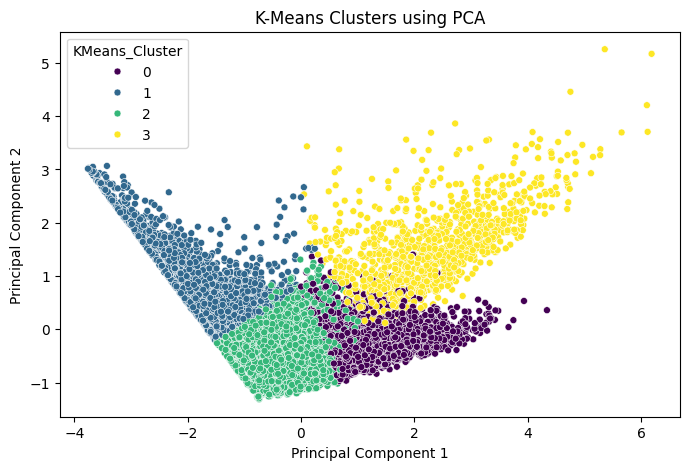

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["KMeans_Cluster"],
    palette="viridis",
    s=25
)

plt.title("K-Means Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

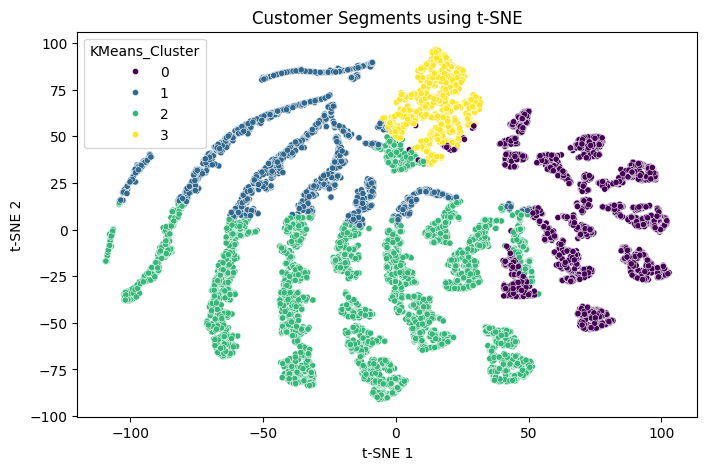

In [14]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm["KMeans_Cluster"],
    palette="viridis",
    s=20
)

plt.title("Customer Segments using t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

In [15]:
cluster_summary = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

display(cluster_summary)

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,27.33,12.78,23134.21
1,165.51,3.18,5080.68
2,45.30,5.07,8204.66
3,37.84,9.87,83208.68
